In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
df=pd.read_csv("insurance_claims.csv")
df.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,1406.91,0,466132,...,YES,71610,6510,13020,52080,Saab,92x,2004,Y,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,1197.22,5000000,468176,...,?,5070,780,780,3510,Mercedes,E400,2007,Y,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,1413.14,5000000,430632,...,NO,34650,7700,3850,23100,Dodge,RAM,2007,N,NaN
3,256,41,227811,1990-05-25,IL,250/500,2000,1415.74,6000000,608117,...,NO,63400,6340,6340,50720,Chevrolet,Tahoe,2014,Y,NaN
4,228,44,367455,2014-06-06,IL,500/1000,1000,1583.91,6000000,610706,...,NO,6500,1300,650,4550,Accura,RSX,2009,N,NaN


In [4]:
df.isin(['' ,'NA','-']).sum().any()

np.False_

In [5]:
df.isin(['?']).sum().any()

np.True_

In [6]:
df=df.replace('?',np.nan)

In [7]:
df.isnull().sum()

months_as_customer                0
age                               0
policy_number                     0
policy_bind_date                  0
policy_state                      0
policy_csl                        0
policy_deductable                 0
policy_annual_premium             0
umbrella_limit                    0
insured_zip                       0
insured_sex                       0
insured_education_level           0
insured_occupation                0
insured_hobbies                   0
insured_relationship              0
capital-gains                     0
capital-loss                      0
incident_date                     0
incident_type                     0
collision_type                  178
incident_severity                 0
authorities_contacted            91
incident_state                    0
incident_city                     0
incident_location                 0
incident_hour_of_the_day          0
number_of_vehicles_involved       0
property_damage             

In [8]:
df['property_damage'].fillna(df['property_damage'].mode()[0],inplace=True)
df['police_report_available'].fillna(df['police_report_available'].mode()[0],inplace=True)
df['collision_type'].fillna(df['collision_type'].mode()[0],inplace=True)

C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\3181624150.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['property_damage'].fillna(df['property_damage'].mode()[0],inplace=True)
C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\3181624150.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [9]:
df['authorities_contacted'].fillna('NA',inplace=True)

C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\1114006001.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['authorities_contacted'].fillna('NA',inplace=True)


In [10]:
# Droping unnecessary columns
df.drop(['_c39','incident_location','insured_zip','policy_number'],axis=1,inplace=True)

In [11]:
df['policy_csl'].value_counts()

policy_csl
250/500     351
100/300     349
500/1000    300
Name: count, dtype: int64

In [12]:
# Spliting and extracting policy_csl at '/'  ( slash se pehle ka data aur slash ke baad ko lekr unke alag column ban gaye 
df['CSL_Personal']=df.policy_csl.str.split('/',expand=True)[0]  # policy csl column hai 
df['CSL_Accidental']=df.policy_csl.str.split('/',expand=True)[1]

In [13]:
# Now we can drop policy_csl column 
df.drop("policy_csl",axis=1,inplace=True)

In [14]:
# Converting Date columns from object type into datetime data type
df['policy_bind_date']=pd.to_datetime(df['policy_bind_date'])
df['incident_date']=pd.to_datetime(df['incident_date'])

In [15]:
# Extracting Day, Month and Year column from policy_bind_date
df['policy_bind_day'] = df['policy_bind_date'].dt.day
df['policy_bind_month'] = df['policy_bind_date'].dt.month
df['policy_bind_year'] = df['policy_bind_date'].dt.year

# Extracting Day, Month and Year column from incident_date
df['incident_day'] = df['incident_date'].dt.day
df['incident_month'] = df['incident_date'].dt.month
df['incident_year'] = df['incident_date'].dt.year

In [16]:
# Since Extraction is done now we can Drop policy_bind_date and incident_date columns
df.drop(['policy_bind_date','incident_date'],axis=1,inplace=True)

In [17]:
# Incident year for all data is 2015 so we gone drop it.
df.drop(['incident_year'],axis=1,inplace=True)

In [18]:
df['auto_year'].value_counts()

auto_year
1995    56
1999    55
2005    54
2006    53
2011    53
2007    52
2003    51
2009    50
2010    50
2013    49
2002    49
2015    47
1997    46
2012    46
2008    45
2014    44
2001    42
2000    42
1998    40
2004    39
1996    37
Name: count, dtype: int64

In [19]:
# Lets extract age of the vehicle from auto_year by subtracting it from the year 2015
df['Automobile_Age']=2015 - df['auto_year'] 
# Droping auto year column
df.drop("auto_year",axis=1,inplace=True)

In [20]:
# this data is of 2015 year and to know the age of veichle subtract from 15 

In [21]:
df['Automobile_Age'].value_counts()

Automobile_Age
20    56
16    55
10    54
9     53
4     53
8     52
12    51
6     50
5     50
2     49
13    49
0     47
18    46
3     46
7     45
1     44
14    42
15    42
17    40
11    39
19    37
Name: count, dtype: int64

In [22]:
category=df.select_dtypes(include='object')
numerical=df.select_dtypes(exclude='object')

In [23]:
category

,policy_state,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,property_damage,police_report_available,auto_make,auto_model,fraud_reported,CSL_Personal,CSL_Accidental
0,OH,MALE,MD,craft-repair,sleeping,husband,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,YES,YES,Saab,92x,Y,250,500
1,IN,MALE,MD,machine-op-inspct,reading,other-relative,Vehicle Theft,Rear Collision,Minor Damage,Police,VA,Riverwood,NO,NO,Mercedes,E400,Y,250,500
2,OH,FEMALE,PhD,sales,board-games,own-child,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,NO,NO,Dodge,RAM,N,100,300
3,IL,FEMALE,PhD,armed-forces,board-games,unmarried,Single Vehicle Collision,Front Collision,Major Damage,Police,OH,Arlington,NO,NO,Chevrolet,Tahoe,Y,250,500
4,IL,MALE,Associate,sales,board-games,unmarried,Vehicle Theft,Rear Collision,Minor Damage,NA,NY,Arlington,NO,NO,Accura,RSX,N,500,1000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,OH,FEMALE,Masters,craft-repair,paintball,unmarried,Single Vehicle Collision,Front Collision,Minor Damage,Fire,NC,Northbrook,YES,NO,Honda,Accord,N,500,1000
996,IL,FEMALE,PhD,prof-specialty,sleeping,wife,Single Vehicle Collision,Rear Collision,Major Damage,Fire,SC,Northbend,YES,NO,Volkswagen,Passat,N,100,300
997,OH,FEMALE,Masters,armed-forces,bungie-jumping,other-relative,Multi-vehicle Collision,Side Collision,Minor Damage,Police,NC,Arlington,NO,YES,Suburu,Impreza,N,250,500
998,IL,MALE,Associate,handlers-cleaners,base-jumping,wife,Single Vehicle Collision,Rear Collision,Major Damage,Other,NY,Arlington,NO,YES,Audi,A5,N,500,1000


In [24]:
numerical

,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,...,total_claim_amount,injury_claim,property_claim,vehicle_claim,policy_bind_day,policy_bind_month,policy_bind_year,incident_day,incident_month,Automobile_Age
0,328,48,1000,1406.91,0,53300,0,5,1,1,...,71610,6510,13020,52080,17,10,2014,25,1,11
1,228,42,2000,1197.22,5000000,0,0,8,1,0,...,5070,780,780,3510,27,6,2006,21,1,8
2,134,29,2000,1413.14,5000000,35100,0,7,3,2,...,34650,7700,3850,23100,6,9,2000,22,2,8
3,256,41,2000,1415.74,6000000,48900,-62400,5,1,1,...,63400,6340,6340,50720,25,5,1990,10,1,1
4,228,44,1000,1583.91,6000000,66000,-46000,20,1,0,...,6500,1300,650,4550,6,6,2014,17,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,3,38,1000,1310.80,0,0,0,20,1,0,...,87200,17440,8720,61040,16,7,1991,22,2,9
996,285,41,1000,1436.79,0,70900,0,23,1,2,...,108480,18080,18080,72320,5,1,2014,24,1,0
997,130,34,500,1383.49,3000000,35100,0,4,3,2,...,67500,7500,7500,52500,17,2,2003,23,1,19
998,458,62,2000,1356.92,5000000,0,0,2,1,0,...,46980,5220,5220,36540,18,11,2011,26,2,17


In [25]:
for i in category:
    print(i)
    print(df[i].value_counts())
    print('-'*100)

policy_state
policy_state
OH    352
IL    338
IN    310
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
insured_sex
insured_sex
FEMALE    537
MALE      463
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
insured_education_level
insured_education_level
JD             161
High School    160
Associate      145
MD             144
Masters        143
PhD            125
College        122
Name: count, dtype: int64
----------------------------------------------------------------------------------------------------
insured_occupation
insured_occupation
machine-op-inspct    93
prof-specialty       85
tech-support         78
sales                76
exec-managerial      76
craft-repair         74
transport-moving     72
priv-house-serv      71
other-service        71
armed-forces         69
adm-clerical         65
protective-serv      63
hand

<Figure size 640x480 with 0 Axes>

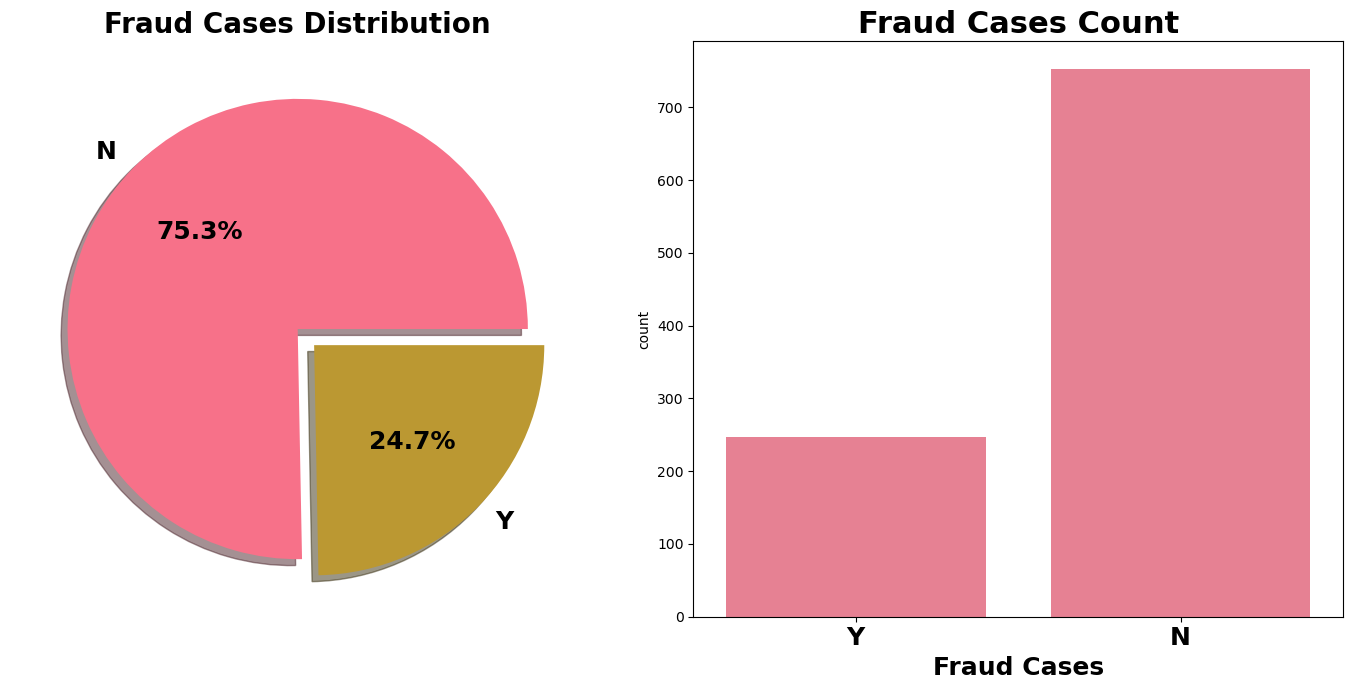

In [26]:
plt.rcParams["figure.autolayout"] = True # When set to True, Matplotlib internally behaves somewhat like calling 
plt.tight_layout()  #  every figure, but it only considers titles, axis labels, and tick labels — it does not account for legends or annotations outside the axes.
sns.set_palette('husl')
f,ax=plt.subplots(1,2,figsize=(14,7))
df['fraud_reported'].value_counts().plot.pie(explode=[0,0.1],autopct='%3.1f%%',
                                          textprops ={ 'fontweight': 'bold','fontsize':18}, ax=ax[0],shadow=True)
ax[0].set_title('Fraud Cases Distribution', fontsize=20,fontweight ='bold')
ax[0].set_ylabel('')
sns.countplot(x='fraud_reported',data=df,ax=ax[1])
ax[1].set_title('Fraud Cases Count',fontsize=22,fontweight ='bold')
ax[1].set_xlabel("Fraud Cases",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=18,fontweight ='bold')
plt.show()

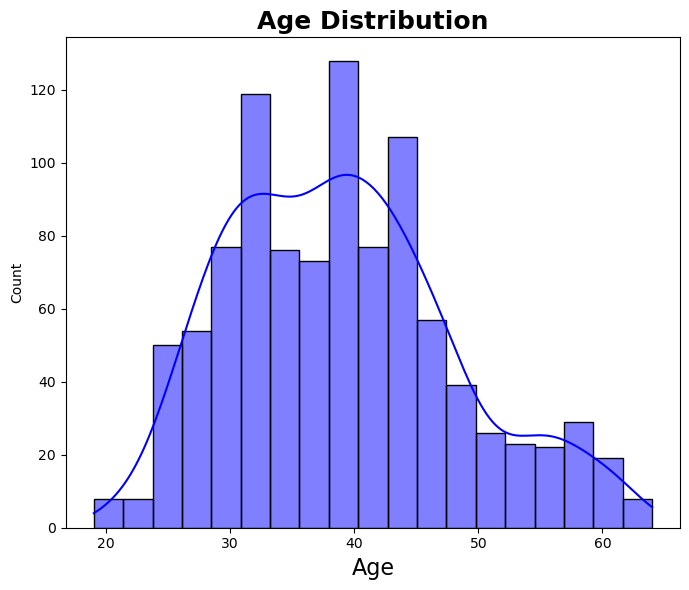

In [27]:
plt.figure(figsize=(7,6))  # age ka histogram
sns.histplot(df.age,kde=True, color='b')
plt.xlabel('Age',fontsize=16)  # kde se ye line bani aati hai curve wali 
plt.title('Age Distribution', fontsize=18,fontweight ='bold')
plt.show()

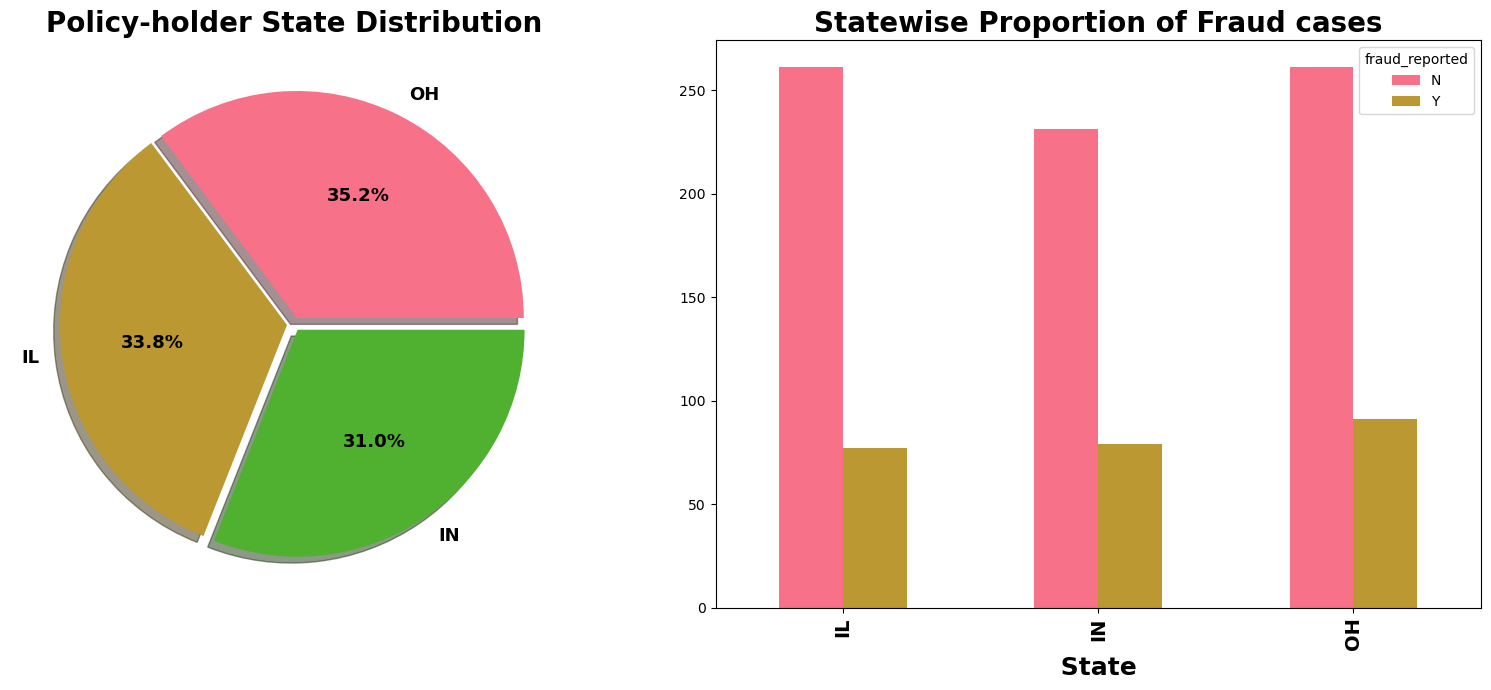

In [28]:
plt.rcParams["figure.autolayout"] = True
sns.set_palette('husl')
fig,ax=plt.subplots(1,2,figsize=(16,7))
df['policy_state'].value_counts().plot.pie(explode=[0.03,0.03,0.03],autopct='%2.1f%%',
                                          textprops ={ 'fontweight': 'bold','fontsize':13}, ax=ax[0],shadow=True)
ax[0].set_title('Policy-holder State Distribution', fontsize=20,fontweight ='bold')
ax[0].set_ylabel('')

table = pd.crosstab(df['policy_state'], df['fraud_reported'])
table.plot(kind = 'bar', ax=ax[1])
ax[1].set_title('Statewise Proportion of Fraud cases',fontsize=20,fontweight ='bold')
ax[1].set_xlabel(" State ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.tight_layout()
plt.show()

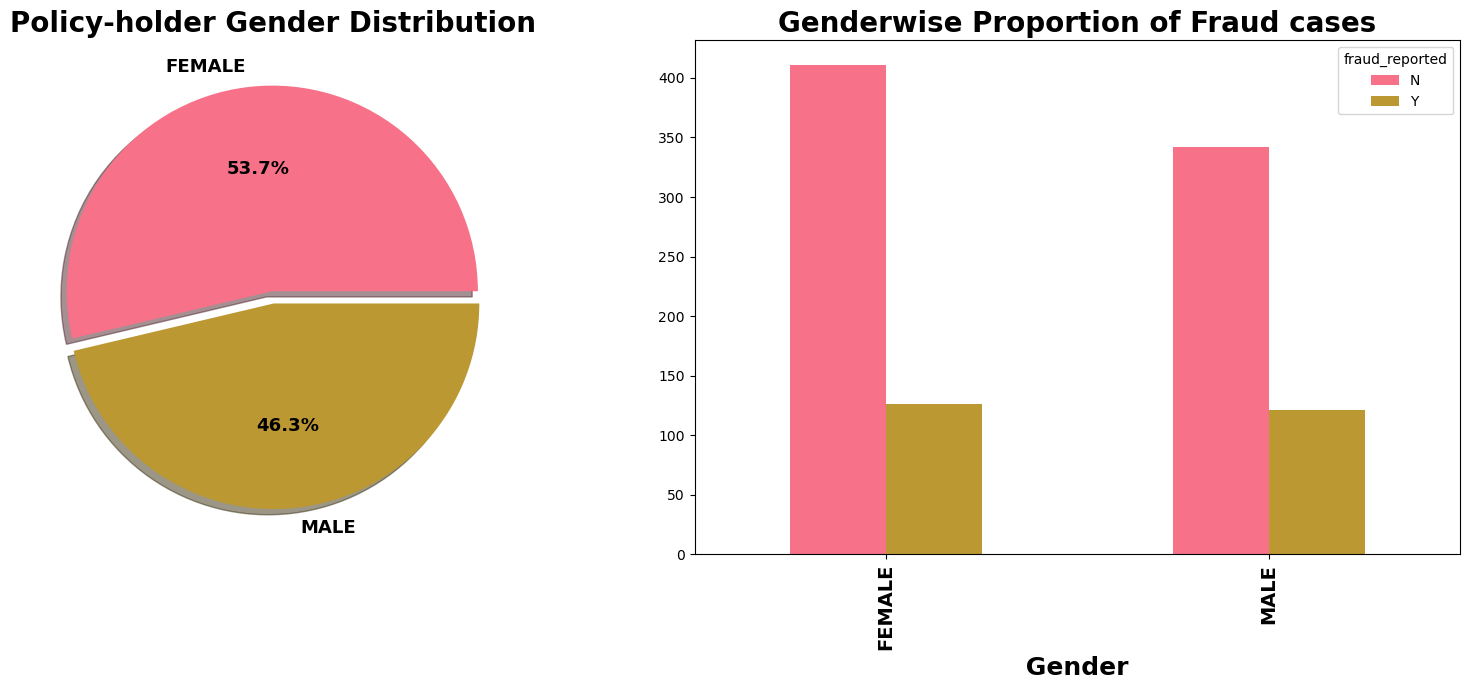

In [29]:
# gender and fraud cases 
plt.rcParams["figure.autolayout"] = True
sns.set_palette('husl')
fig,ax=plt.subplots(1,2,figsize=(16,7))
df['insured_sex'].value_counts().plot.pie(explode=[0.03,0.03],autopct='%2.1f%%',
                                          textprops ={ 'fontweight': 'bold','fontsize':13}, ax=ax[0],shadow=True)
ax[0].set_title('Policy-holder Gender Distribution', fontsize=20,fontweight ='bold')
ax[0].set_ylabel('')

table = pd.crosstab(df['insured_sex'], df['fraud_reported'])
table.plot(kind = 'bar', ax=ax[1])
ax[1].set_title('Genderwise Proportion of Fraud cases',fontsize=20,fontweight ='bold')
ax[1].set_xlabel(" Gender ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.tight_layout()
plt.show()

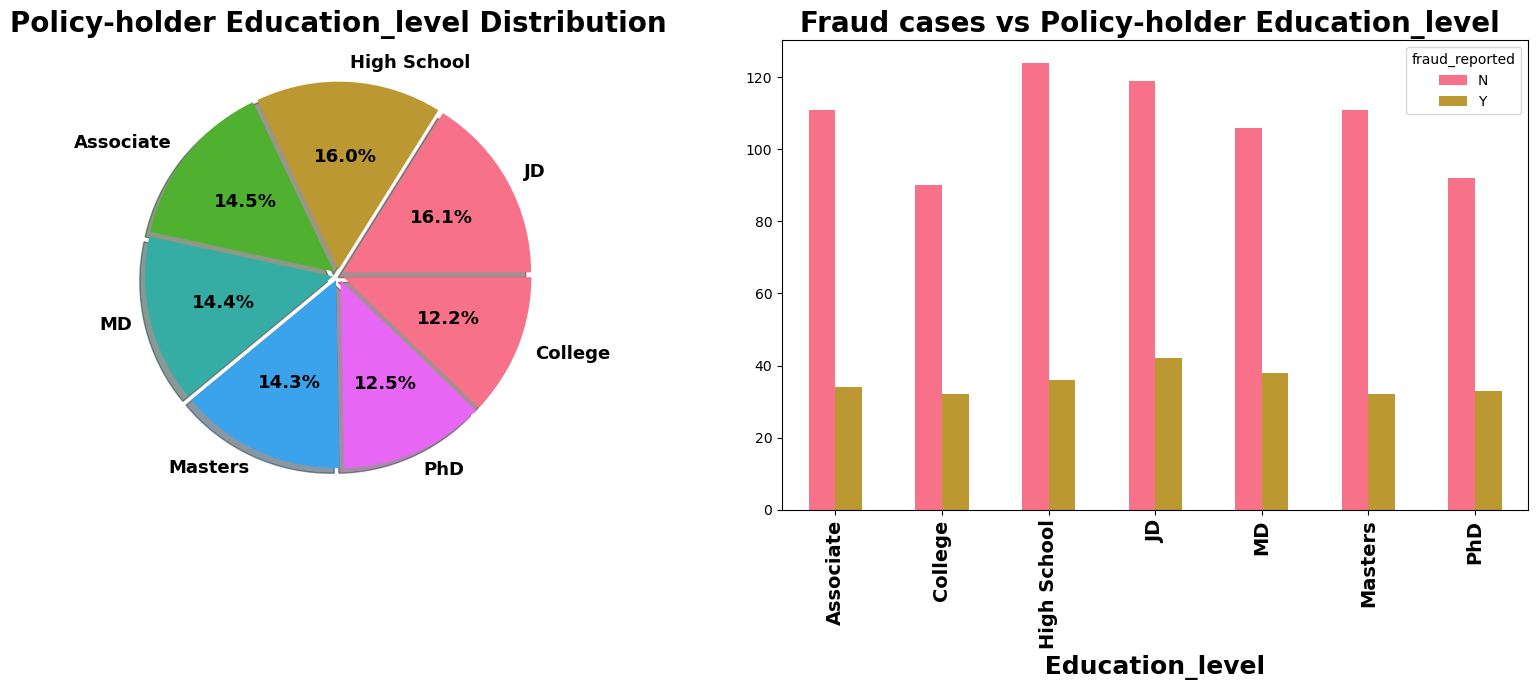

In [30]:
# education of culprits  on fraud basis 
plt.rcParams["figure.autolayout"] = True
sns.set_palette('husl')
fig,ax=plt.subplots(1,2,figsize=(16,7))
df['insured_education_level'].value_counts().plot.pie(explode=[0.03,0.03,0.03,0.03,0.03,0.03,.03],autopct='%2.1f%%',
                                          textprops ={ 'fontweight': 'bold','fontsize':13}, ax=ax[0],shadow=True)
ax[0].set_title('Policy-holder Education_level Distribution', fontsize=20,fontweight ='bold')
ax[0].set_ylabel('')

table = pd.crosstab(df['insured_education_level'], df['fraud_reported'])
table.plot(kind = 'bar', ax=ax[1])
ax[1].set_title('Fraud cases vs Policy-holder Education_level ',fontsize=20,fontweight ='bold')
ax[1].set_xlabel(" Education_level ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold')
plt.tight_layout()
plt.show()

C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\463252981.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['insured_occupation'], palette = 'gist_earth')


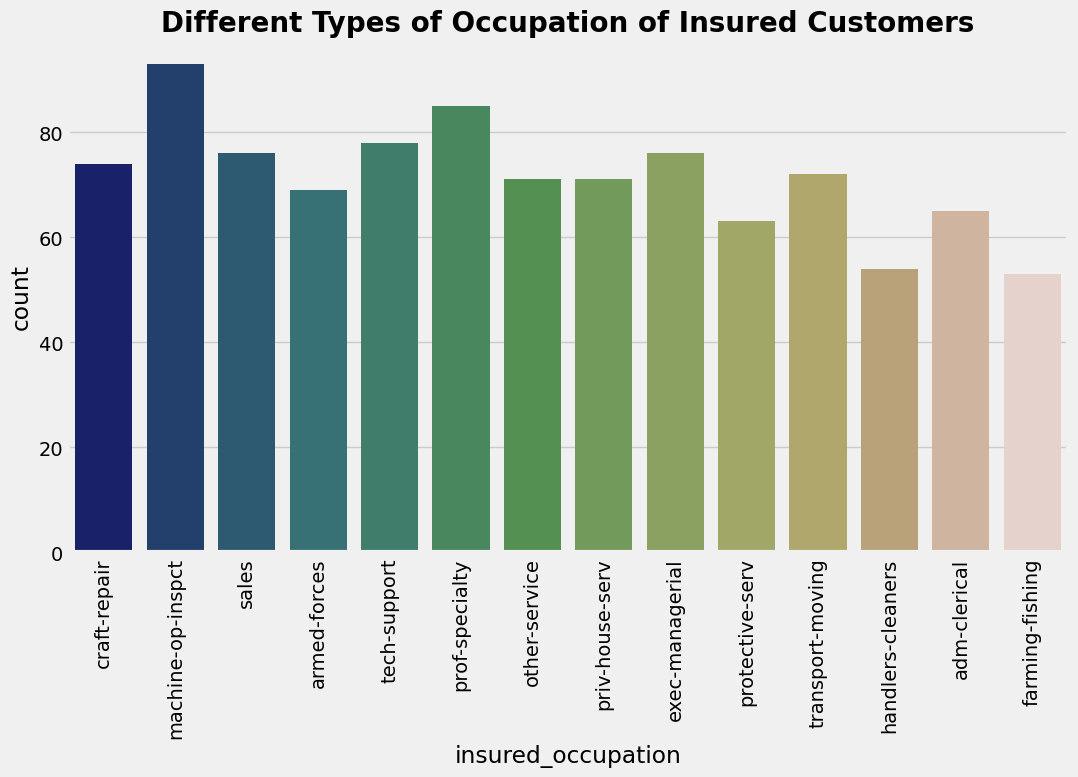

In [31]:
# let's check the insured occupation
plt.style.use('fivethirtyeight')
plt.rcParams['figure.figsize'] = (11, 8)
sns.countplot(x=df['insured_occupation'], palette = 'gist_earth')
plt.title('Different Types of Occupation of Insured Customers' ,fontsize=20,fontweight ='bold')
plt.xticks(rotation = 90)
plt.show()

C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\3597202234.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['insured_hobbies'], palette = 'cool')


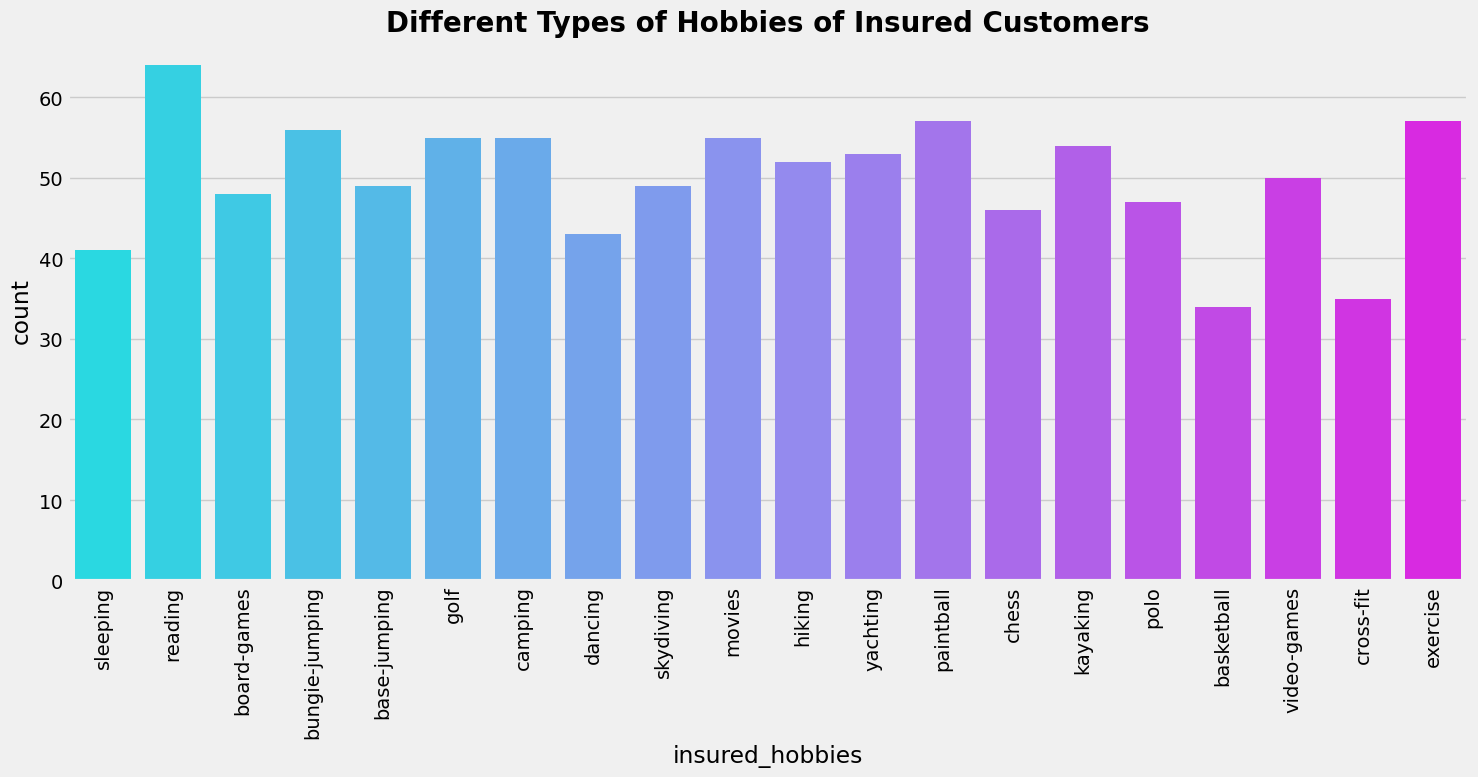

In [32]:
# let's check the insured hobbies
plt.style.use('fivethirtyeight')
plt.rcParams['figure.figsize'] = (15, 8)
sns.countplot(x=df['insured_hobbies'], palette = 'cool')
plt.title('Different Types of Hobbies of Insured Customers',fontsize=20,fontweight ='bold')
plt.xticks(rotation = 90)
plt.show()

C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\4269705010.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['incident_type'], palette = 'Dark2')


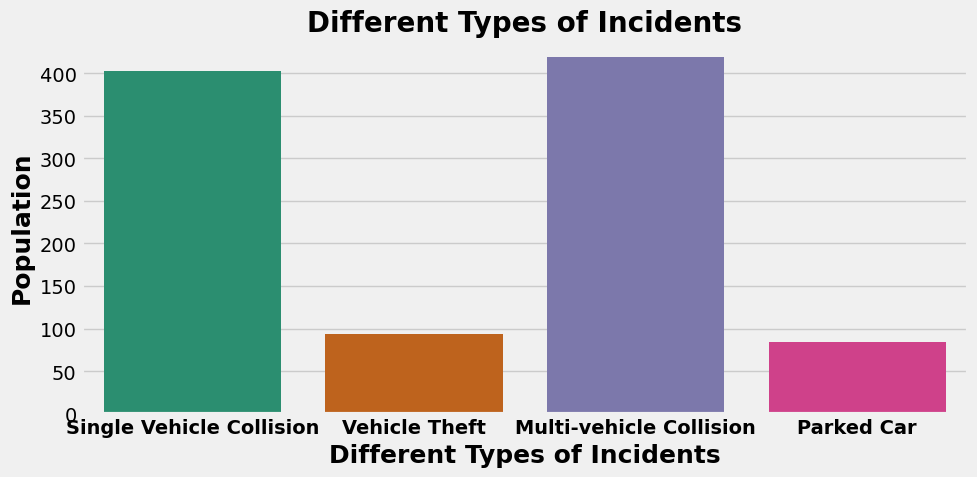

In [33]:
# let's check the incident types
plt.rcParams['figure.figsize'] = (10,5)
sns.countplot(x=df['incident_type'], palette = 'Dark2')
plt.title('Different Types of Incidents',fontsize=20,fontweight ='bold')
plt.xlabel('Different Types of Incidents', fontsize=18,fontweight='bold')
plt.ylabel('Population', fontsize=18,fontweight='bold')
plt.xticks(fontweight ='bold')
plt.show()

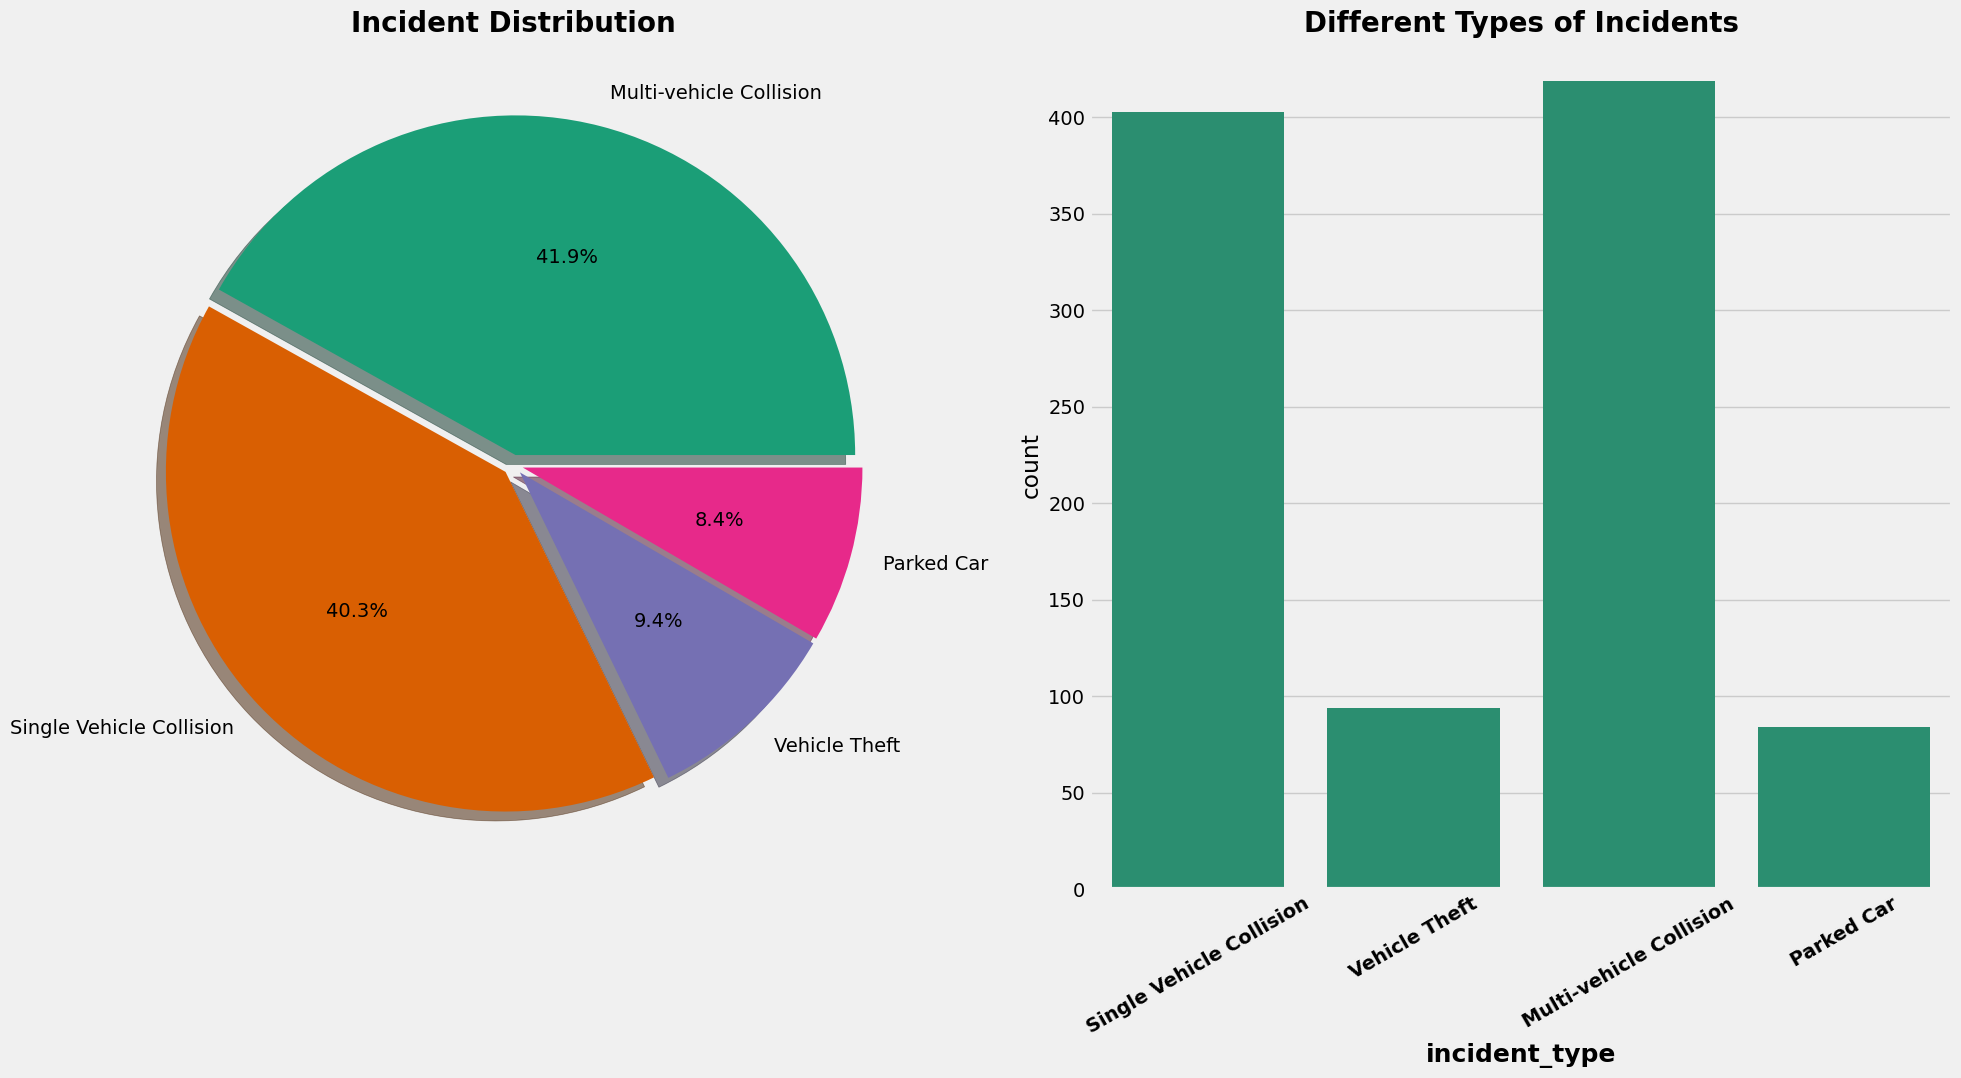

In [34]:
plt.rcParams["figure.autolayout"] = True
sns.set_palette('Dark2')
f,ax=plt.subplots(1,2,figsize=(20,11))
df['incident_type'].value_counts().plot.pie(explode=[0.03,.03,.03,.03],autopct='%3.1f%%',
                                          textprops ={ 'fontsize':14}, ax=ax[0],shadow=True)
ax[0].set_title('Incident Distribution', fontsize=20,fontweight ='bold')
ax[0].set_ylabel('')
sns.countplot(x='incident_type',data=df,ax=ax[1])
ax[1].set_title('Different Types of Incidents',fontsize=20,fontweight ='bold')
ax[1].set_xlabel("incident_type",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,rotation=30,fontweight ='bold')
plt.tight_layout()
plt.show()

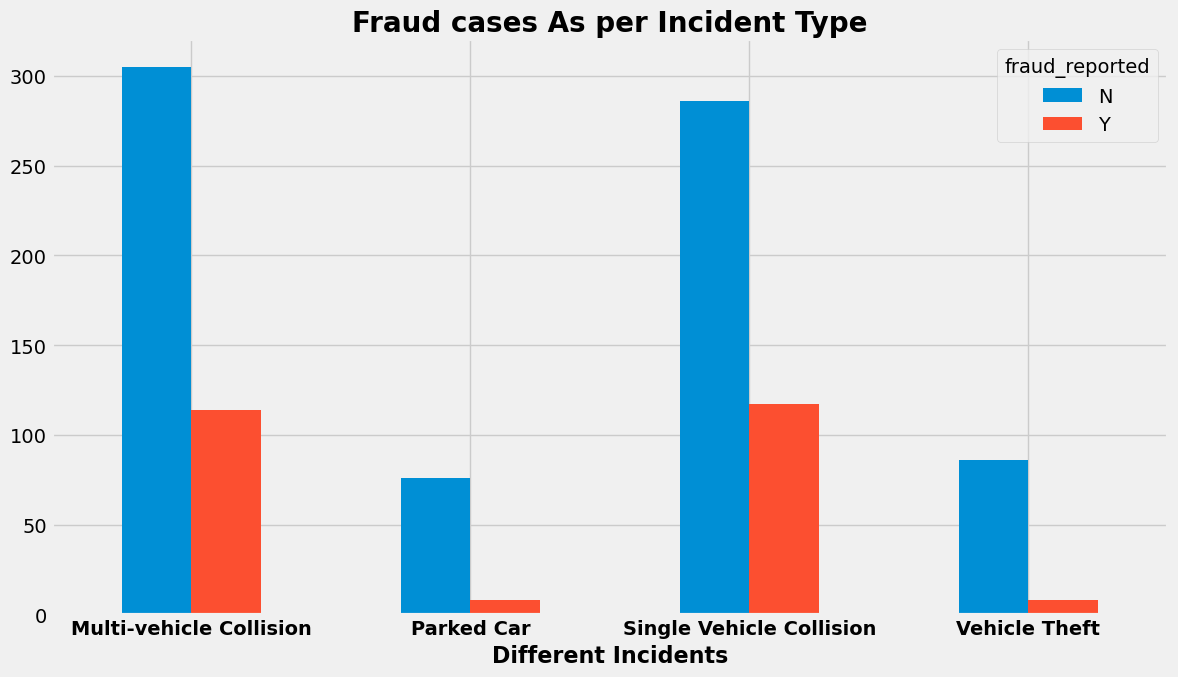

In [35]:
# let's check the insured hobbies
plt.style.use('fivethirtyeight')
plt.rcParams['figure.figsize'] = (12,7)
table = pd.crosstab(df['incident_type'], df['fraud_reported'])
table.plot(kind = 'bar')
plt.title('Fraud cases As per Incident Type',fontsize=20,fontweight ='bold')
plt.xlabel('Different Incidents', fontsize=16,fontweight='bold')
plt.xticks(fontsize=14,rotation=0,fontweight ='bold')
plt.show()

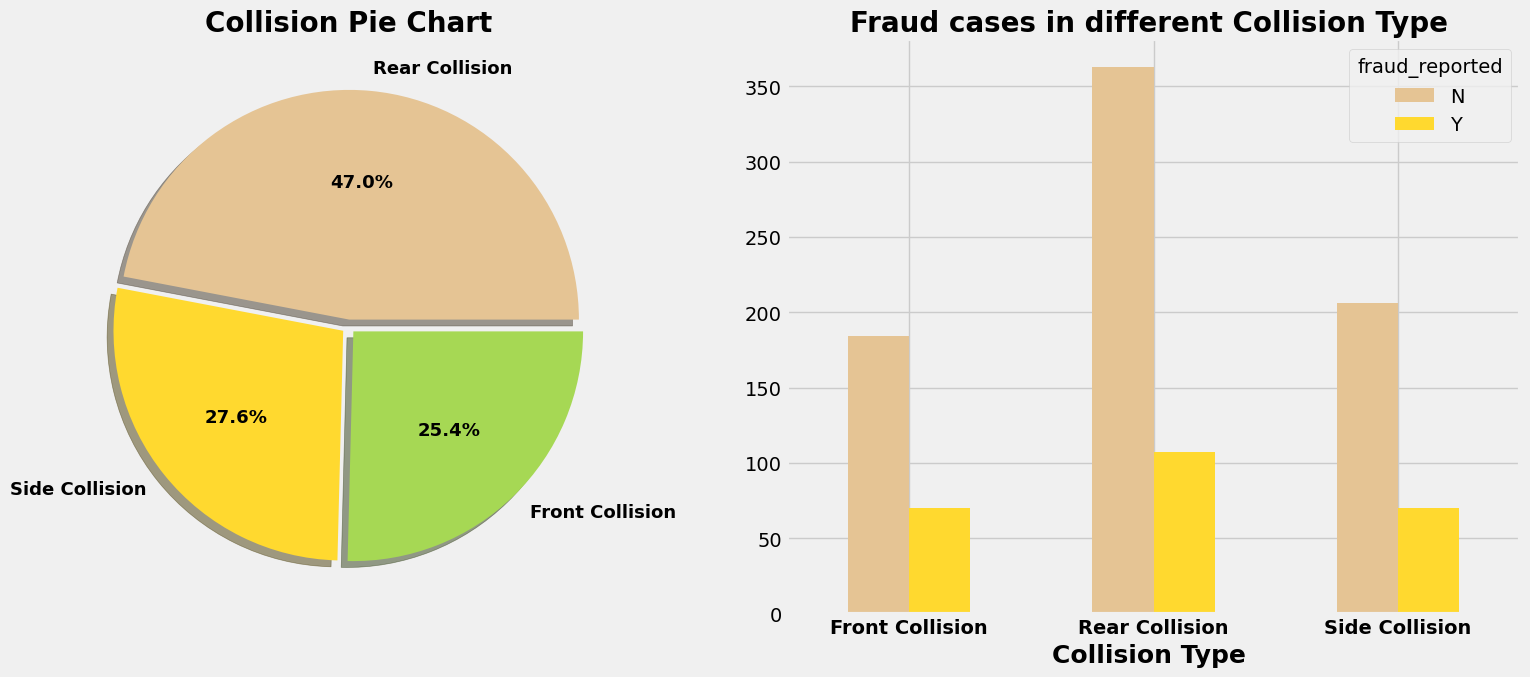

In [36]:
plt.rcParams["figure.autolayout"] = True
sns.set_palette('Set2_r')
fig,ax=plt.subplots(1,2,figsize=(16,7))
df['collision_type'].value_counts().plot.pie(explode=[0.03,0.03,0.03],autopct='%2.1f%%',
                                          textprops ={ 'fontweight': 'bold','fontsize':13}, ax=ax[0],shadow=True)
ax[0].set_title('Collision Pie Chart', fontsize=20,fontweight ='bold')
ax[0].set_ylabel('')

table = pd.crosstab(df['collision_type'], df['fraud_reported'])
table.plot(kind = 'bar', ax=ax[1])
ax[1].set_title('Fraud cases in different Collision Type ',fontsize=20,fontweight ='bold')
ax[1].set_xlabel("Collision Type ",fontsize=18,fontweight ='bold')
plt.xticks(fontsize=14,fontweight ='bold',rotation=0)
plt.tight_layout()
plt.show()

In [37]:
numerical

,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,bodily_injuries,...,total_claim_amount,injury_claim,property_claim,vehicle_claim,policy_bind_day,policy_bind_month,policy_bind_year,incident_day,incident_month,Automobile_Age
0,328,48,1000,1406.91,0,53300,0,5,1,1,...,71610,6510,13020,52080,17,10,2014,25,1,11
1,228,42,2000,1197.22,5000000,0,0,8,1,0,...,5070,780,780,3510,27,6,2006,21,1,8
2,134,29,2000,1413.14,5000000,35100,0,7,3,2,...,34650,7700,3850,23100,6,9,2000,22,2,8
3,256,41,2000,1415.74,6000000,48900,-62400,5,1,1,...,63400,6340,6340,50720,25,5,1990,10,1,1
4,228,44,1000,1583.91,6000000,66000,-46000,20,1,0,...,6500,1300,650,4550,6,6,2014,17,2,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,3,38,1000,1310.80,0,0,0,20,1,0,...,87200,17440,8720,61040,16,7,1991,22,2,9
996,285,41,1000,1436.79,0,70900,0,23,1,2,...,108480,18080,18080,72320,5,1,2014,24,1,0
997,130,34,500,1383.49,3000000,35100,0,4,3,2,...,67500,7500,7500,52500,17,2,2003,23,1,19
998,458,62,2000,1356.92,5000000,0,0,2,1,0,...,46980,5220,5220,36540,18,11,2011,26,2,17


In [38]:
# Using Label Encoder on categorical variable
from sklearn.preprocessing import LabelEncoder
le =LabelEncoder()
for i in category:
    df[i] = le.fit_transform(df[i])
df.head()

,months_as_customer,age,policy_state,policy_deductable,policy_annual_premium,umbrella_limit,insured_sex,insured_education_level,insured_occupation,insured_hobbies,...,auto_model,fraud_reported,CSL_Personal,CSL_Accidental,policy_bind_day,policy_bind_month,policy_bind_year,incident_day,incident_month,Automobile_Age
0,328,48,2,1000,1406.91,0,1,4,2,17,...,1,1,1,2,17,10,2014,25,1,11
1,228,42,1,2000,1197.22,5000000,1,4,6,15,...,12,1,1,2,27,6,2006,21,1,8
2,134,29,2,2000,1413.14,5000000,0,6,11,2,...,30,0,0,1,6,9,2000,22,2,8
3,256,41,0,2000,1415.74,6000000,0,6,1,2,...,34,1,1,2,25,5,1990,10,1,1
4,228,44,0,1000,1583.91,6000000,1,0,11,2,...,31,0,2,0,6,6,2014,17,2,6


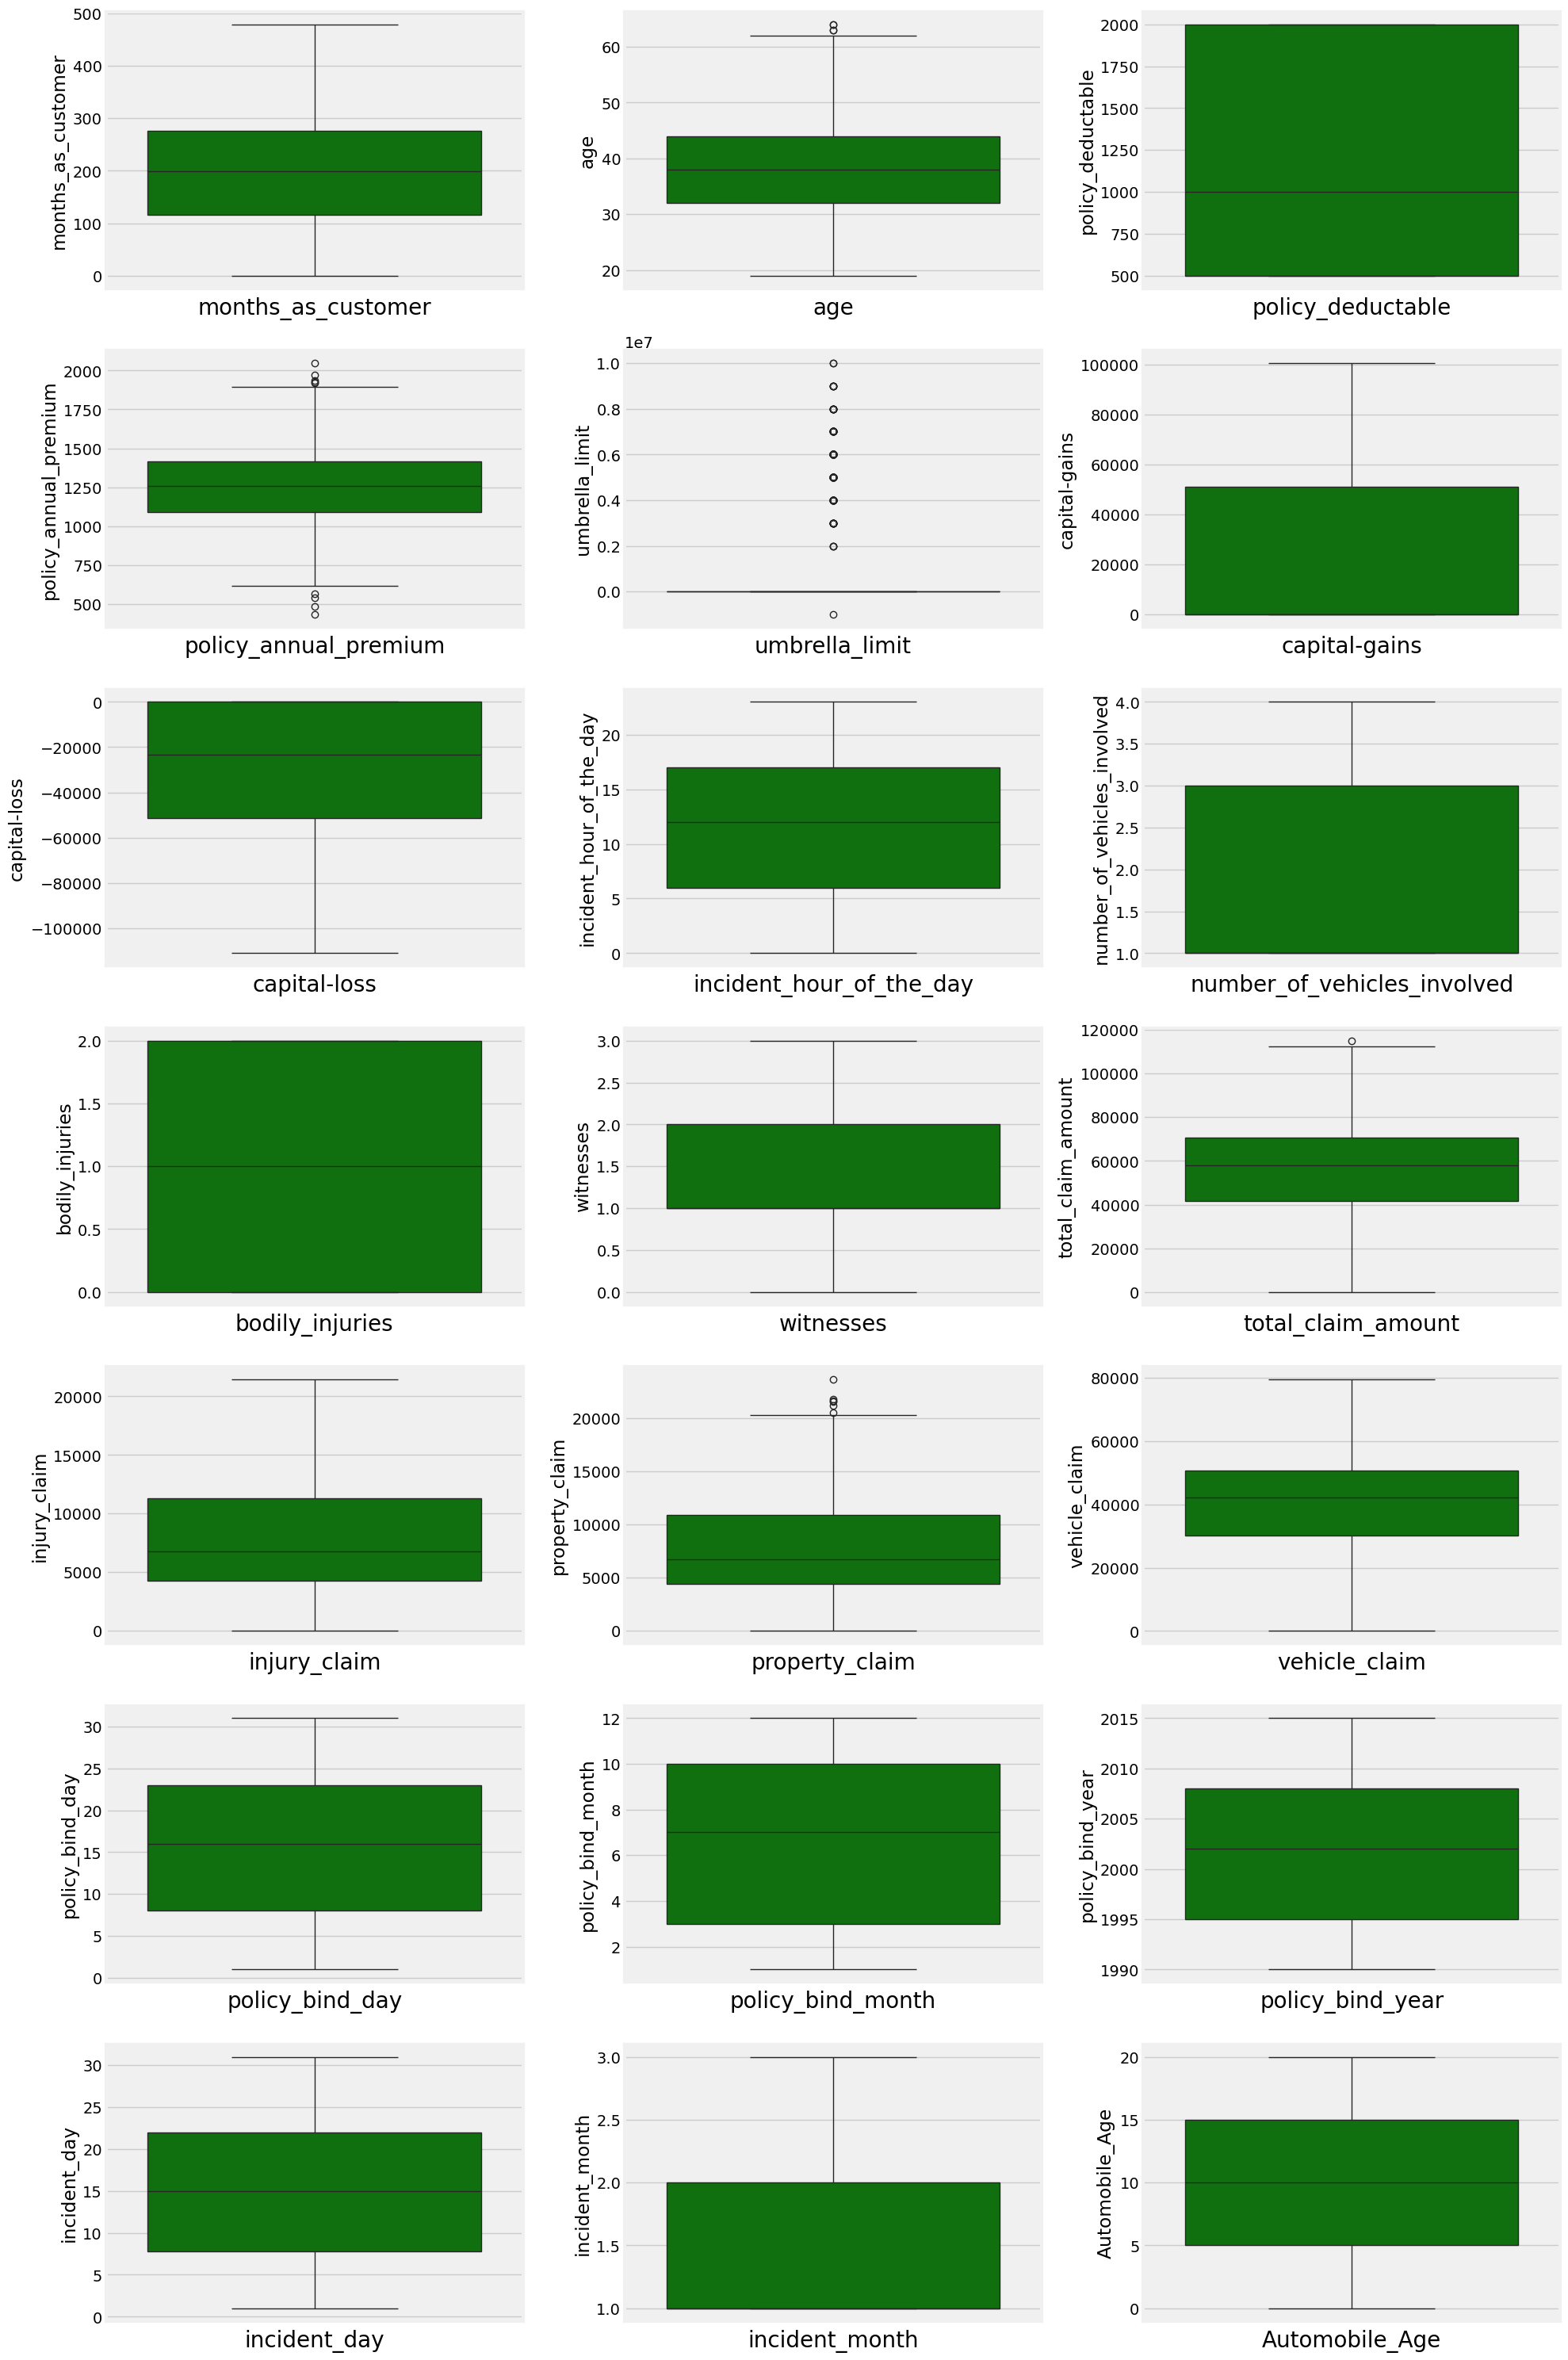

In [39]:
plt.figure(figsize=(20,30),facecolor='white')  # make a figure size for the boxplot 
plotnumber=1   # any vairiable can work 

for column in numerical:   # ek ek krke sare column aayenge numerical se 
    if plotnumber<=21:     #  under 21 
        ax=plt.subplot(7,3,plotnumber)  # subplot dedena 
        sns.boxplot(df[column],color='g')  # har ek column ka boxplot 
        plt.xlabel(column,fontsize=20) # laaabel 
    plotnumber=plotnumber+1  #   ek ek column badhta rhega 
plt.show()

In [40]:
from scipy.stats import zscore
z = np.abs(zscore(df))
threshold = 3
df1 = df[(z<3).all(axis = 1)]

print ("Shape of the dataframe before removing outliers: ", df.shape)
print ("Shape of the dataframe after removing outliers: ", df1.shape)
print ("Percentage of data loss post outlier removal: ", (df.shape[0]-df1.shape[0])/df.shape[0]*100)

df=df1.copy() # reassigning the changed dataframe name to our original dataframe name

Shape of the dataframe before removing outliers:  (1000, 40)
Shape of the dataframe after removing outliers:  (980, 40)
Percentage of data loss post outlier removal:  2.0


C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\1898179806.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[col])
C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\1898179806.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[col])
C:\Users\rizwa\AppData\Local\Temp\ipykernel_9248\18981

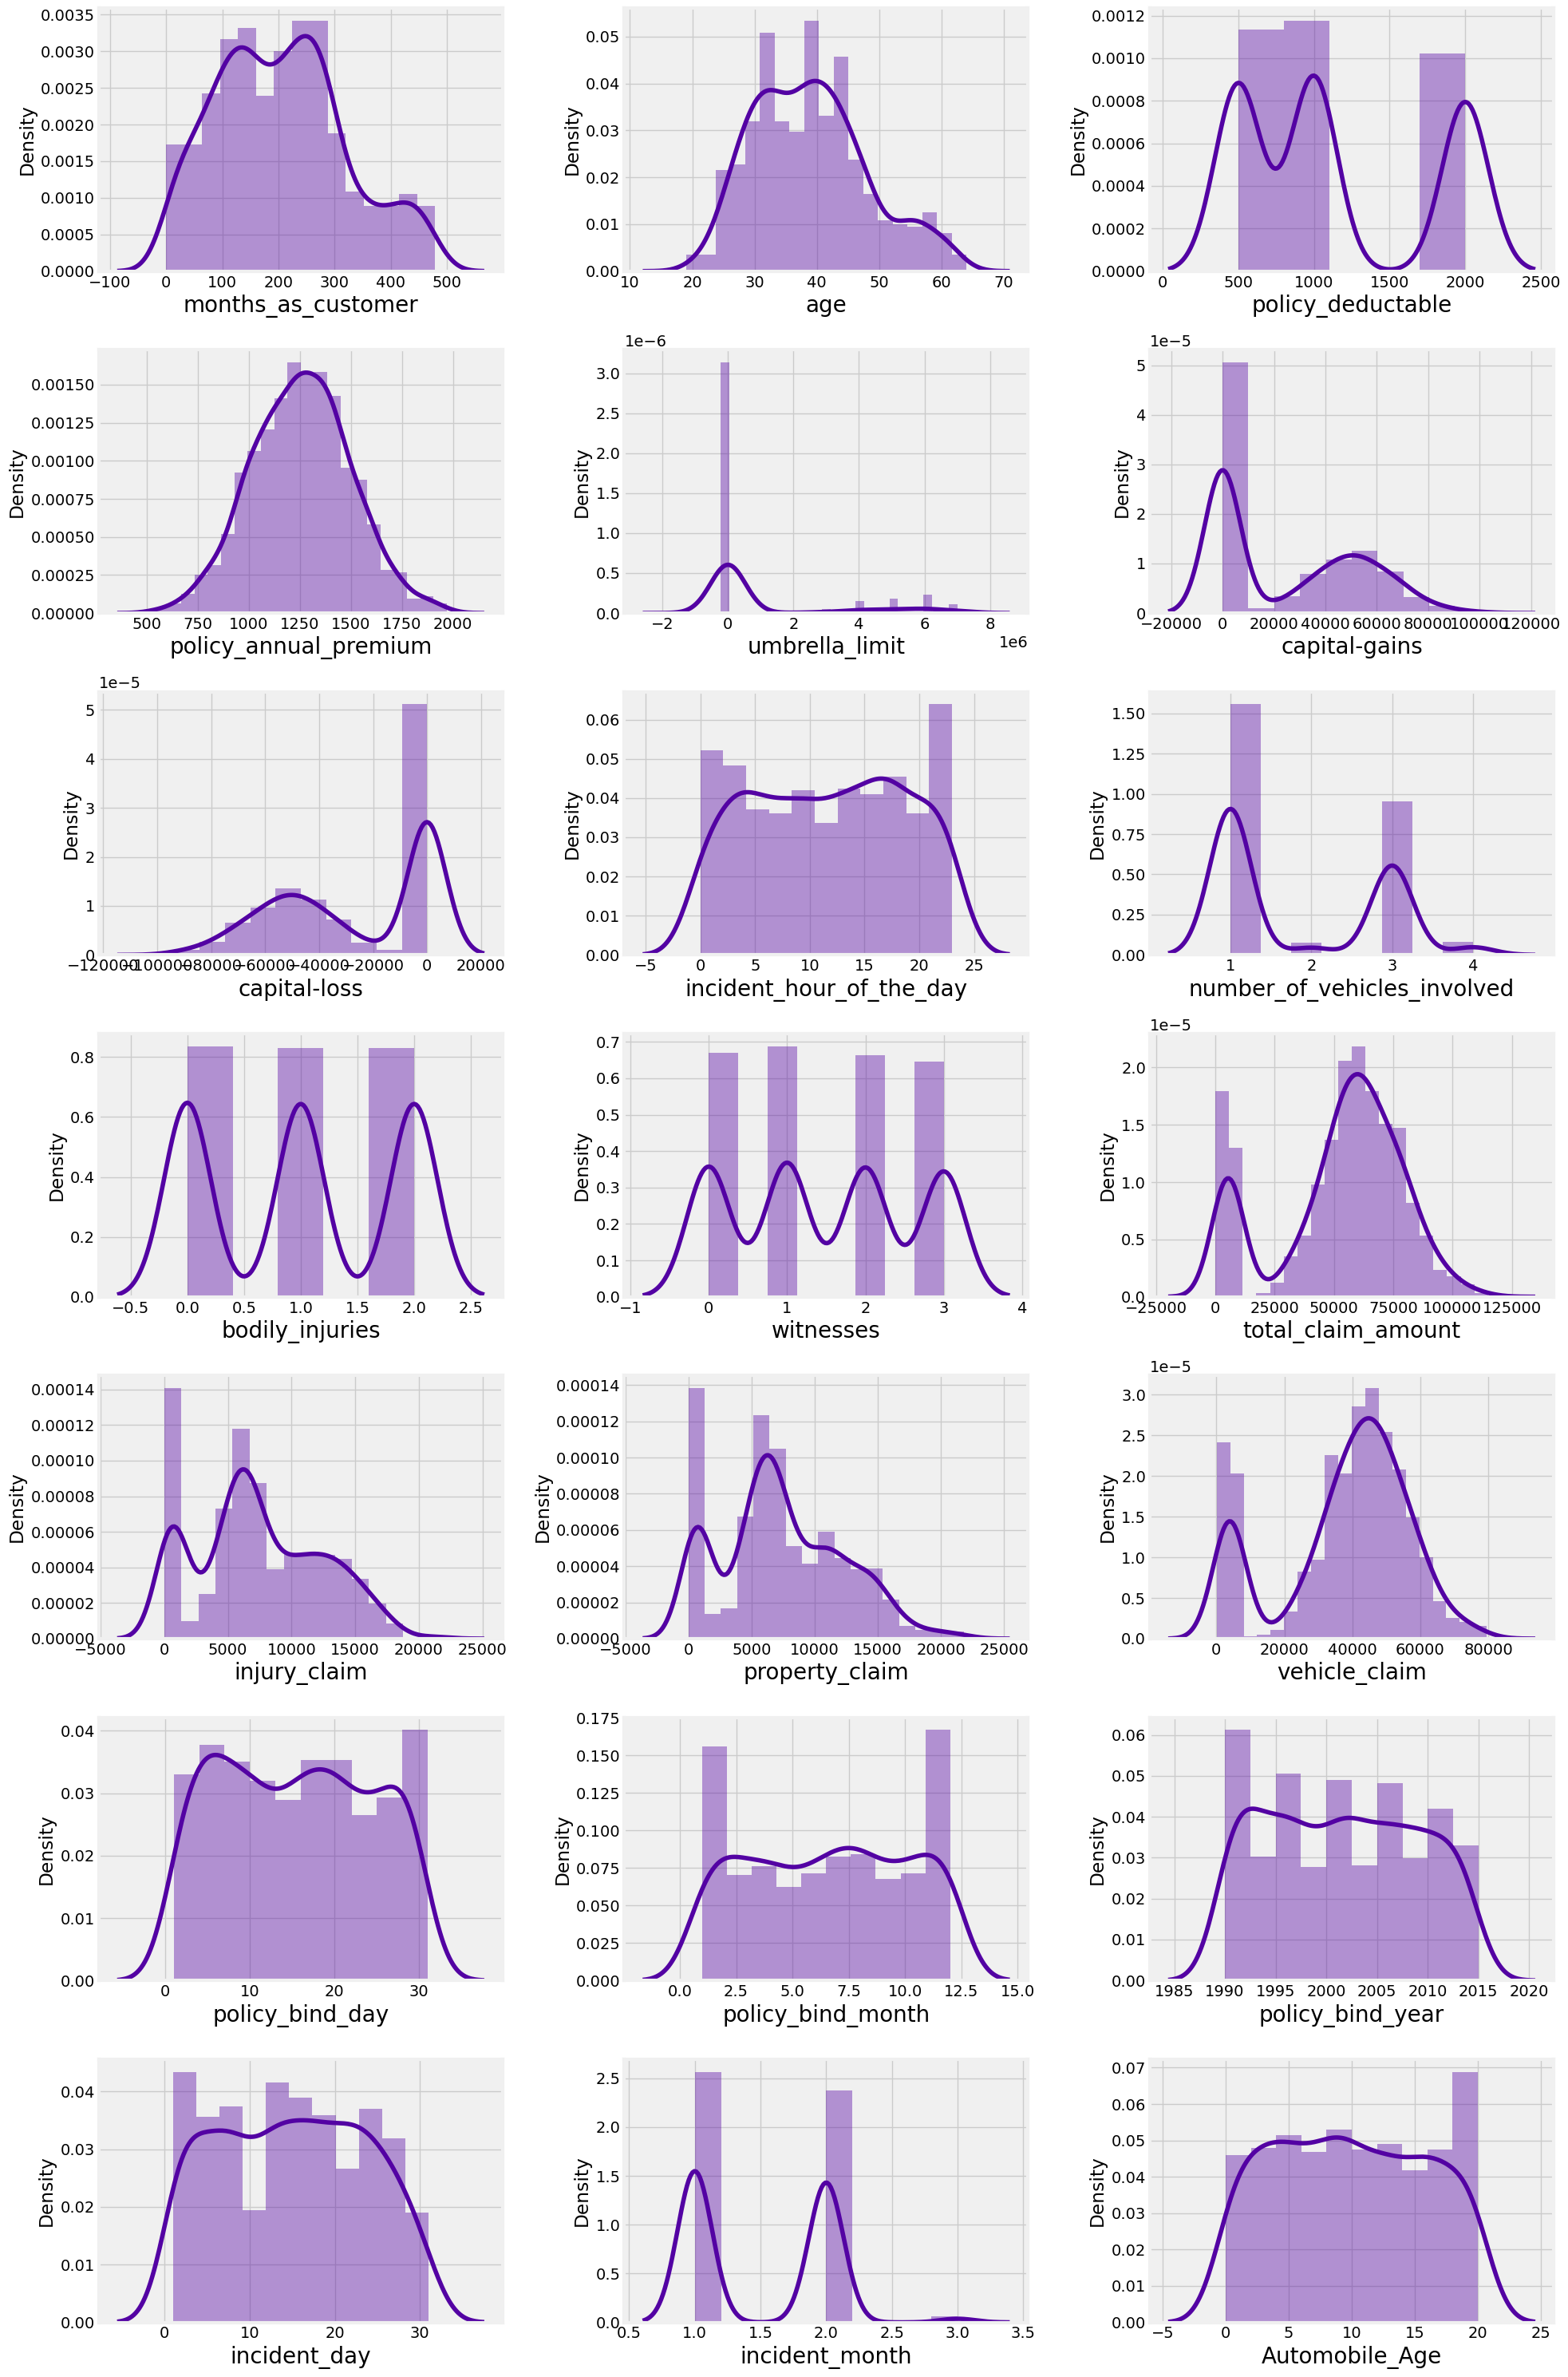

In [41]:
plt.figure(figsize=(20,30),facecolor='white')   # jsi=asie boxplot banaya tha vaise hi distplot bhi bana dia 
sns.set_palette('plasma')
plotnum=1
for col in numerical:
    if plotnum<=21:
        plt.subplot(7,3,plotnum)
        sns.distplot(df[col])
        plt.xlabel(col,fontsize=20)
    plotnum+=1
plt.show()

In [42]:
df.skew()

months_as_customer             0.362608
age                            0.475385
policy_state                  -0.038157
policy_deductable              0.476090
policy_annual_premium          0.035964
umbrella_limit                 1.801424
insured_sex                    0.139324
insured_education_level        0.006286
insured_occupation            -0.055360
insured_hobbies               -0.061488
insured_relationship           0.078339
capital-gains                  0.466619
capital-loss                  -0.376884
incident_type                  0.090563
collision_type                -0.032778
incident_severity              0.277726
authorities_contacted         -0.114044
incident_state                -0.149255
incident_city                  0.043882
incident_hour_of_the_day      -0.039280
number_of_vehicles_involved    0.509725
property_damage                0.853093
bodily_injuries                0.003757
witnesses                      0.026211
police_report_available        0.796221


In [43]:
# Making the skew less than or equal to +0.5 and -0.5 for better prediction using yeo-johnson method
skew=['total_claim_amount','vehicle_claim']  # ye company se discuss krke pata chalta hai ki konsa best rhega 

# Importing Powertransformer
from sklearn.preprocessing import PowerTransformer  # SKEWNESS HATAO 
scaler = PowerTransformer(method='yeo-johnson')

# Transfroming skew data
df[skew] = scaler.fit_transform(df[skew].values)

In [44]:
from imblearn.over_sampling import SMOTE   
X=df.drop(['fraud_reported'],axis=1)
y=df['fraud_reported']

In [45]:
from imblearn.over_sampling import SMOTE # IMBALANCE H TO SMOTE LAGANA PDEGA 
oversample=SMOTE()
X,y=oversample.fit_resample(X,y)

C:\Users\rizwa\.TurboVPN\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\rizwa\.TurboVPN\anaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\rizwa\.TurboVPN\anaconda\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rizwa\.TurboVPN\anaconda\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~

In [46]:
# splitting data in target amd dependentv feature

In [47]:
from sklearn.preprocessing import StandardScaler

In [48]:
sc=StandardScaler()

In [49]:
X_scale=sc.fit_transform(X)

In [50]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,f1_score

In [51]:
maxacc=0
maxrs=0
for i in range(1,250):
    X_train,X_test,y_train,y_test=train_test_split(X_scale,y,test_size=0.2,random_state=i)
    log_reg=LogisticRegression()
    log_reg.fit(X_train,y_train)
    y_pred=log_reg.predict(X_test)
    acc=accuracy_score(y_test,y_pred)
    if acc>maxacc:
        maxacc=acc
        maxrs=i
print(' the best ranodm state ny logistic regression is ' ,maxrs,' and the random state is ',maxacc)
    

 the best ranodm state ny logistic regression is  2  and the random state is  0.8716216216216216


In [52]:
X_train,X_test,y_train,y_test=train_test_split(X_scale,y,random_state=86 ,test_size=0.3)
log_reg.fit(X_train,y_train)   # normally fit krwa dia hai bs 
y_pred=log_reg.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.87      0.85      0.86       236
           1       0.83      0.86      0.85       208

    accuracy                           0.85       444
   macro avg       0.85      0.85      0.85       444
weighted avg       0.85      0.85      0.85       444



In [53]:
from sklearn import neighbors 
from math import sqrt           # knn ki value find krke usme se closest data point ke hisab se aage ka process krenge 
from sklearn.metrics  import mean_squared_error
rmse_val=[]  # store rmse values for differnet k 
for k in range(20):
    k=k+1
    model=neighbors.KNeighborsClassifier(n_neighbors=k)  # 1 se 20 ta sare numbers aayenge aur model m fit ho jayenge for check 

    model.fit(X_train,y_train)  # model ko fit krdo isme 
    y_pred=model.predict(X_test)  # make prediction on test size 
    error=sqrt(mean_squared_error(y_test,y_pred)) # rmse formuale hota hai k nikalne ke liye  
    rmse_val.append(error) # store rmse values 
    print('RMSE calue for k  =',k,'is:',error)        
    


RMSE calue for k  = 1 is: 0.532713603903433
RMSE calue for k  = 2 is: 0.46499055497527714
RMSE calue for k  = 3 is: 0.5714687888035326
RMSE calue for k  = 4 is: 0.5133356733303399
RMSE calue for k  = 5 is: 0.5831724359827805
RMSE calue for k  = 6 is: 0.532713603903433
RMSE calue for k  = 7 is: 0.5851002840046673
RMSE calue for k  = 8 is: 0.5554804754071547
RMSE calue for k  = 9 is: 0.6040404496926218
RMSE calue for k  = 10 is: 0.5753964555687505
RMSE calue for k  = 11 is: 0.6059019038731577
RMSE calue for k  = 12 is: 0.5812381937190964
RMSE calue for k  = 13 is: 0.5965365503100843
RMSE calue for k  = 14 is: 0.5812381937190964
RMSE calue for k  = 15 is: 0.6040404496926218
RMSE calue for k  = 16 is: 0.5889370482885644
RMSE calue for k  = 17 is: 0.6040404496926218
RMSE calue for k  = 18 is: 0.5889370482885644
RMSE calue for k  = 19 is: 0.6151246852292456
RMSE calue for k  = 20 is: 0.602173241362162


In [54]:
X_train, X_test, Y_train, Y_test = train_test_split(X_scale,y, random_state=9, test_size=.3)
log_reg=LogisticRegression()
log_reg.fit(X_train,Y_train)
y_pred=log_reg.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.50      0.43      0.46       236
           1       0.44      0.50      0.47       208

    accuracy                           0.46       444
   macro avg       0.47      0.47      0.46       444
weighted avg       0.47      0.46      0.46       444



In [55]:
 model=[ LogisticRegression(),
        SVC(),                     # sare model ek ek krek usme fit hote rhenge 
        DecisionTreeClassifier(),
        KNeighborsClassifier(n_neighbors = 2),
        RandomForestClassifier()]
        
for m in model:      # model se ek ek krke sari algos aayengi 
    m.fit(X_train,Y_train)   # aur idhar fit ho jayegi 
    y_pred=m.predict(X_test)
    print('Classification ML Algorithm Evaluation Matrix',m,'is' +'\033[0m')
    print('\n')
    print('\033[1m'+'Accuracy Score :'+'\033[0m\n', accuracy_score(Y_test, y_pred))
    print('\n')
    print('\033[1m'+'Confusion matrix :'+'\033[0m \n',confusion_matrix(Y_test, y_pred))
    print('\n')
    print('\033[1m'+'Classification Report :'+'\033[0m \n',classification_report(Y_test, y_pred))
    print('\n')
    print('============================================================================================================')

Classification ML Algorithm Evaluation Matrix LogisticRegression() is


Accuracy Score :
 0.8220720720720721


Confusion matrix : 
 [[176  51]
 [ 28 189]]


Classification Report : 
               precision    recall  f1-score   support

           0       0.86      0.78      0.82       227
           1       0.79      0.87      0.83       217

    accuracy                           0.82       444
   macro avg       0.83      0.82      0.82       444
weighted avg       0.83      0.82      0.82       444



Classification ML Algorithm Evaluation Matrix SVC() is


Accuracy Score :
 0.8671171171171171


Confusion matrix : 
 [[192  35]
 [ 24 193]]


Classification Report : 
               precision    recall  f1-score   support

           0       0.89      0.85      0.87       227
           1       0.85      0.89      0.87       217

    accuracy                           0.87       444
   macro avg       0.87      0.87      0.87       444
weighted avg       0.87      0.87      0.87     

In [56]:
 # Cross-validation is a technique used in machine learning to evaluate the performance of a model on unseen data.
# It involves dividing the available data into multiple folds or subsets, using one of these folds as a validation set, and training the model on the remaining folds. 
from sklearn.model_selection import cross_val_score
model=[LogisticRegression(),
        SVC(),
        DecisionTreeClassifier(),
        KNeighborsClassifier(n_neighbors = 3),
        RandomForestClassifier()]

for m in model:
    score = cross_val_score(m,X_scale,y, cv =5)
    print('\n')
    print('\033[1m'+'Cross Validation Score', m, ':'+'\033[0m\n')
    print("Score :" ,score)
    print("Mean Score :",score.mean())
    print("Std deviation :",score.std())
    print('\n')
    print('============================================================================================================')



Cross Validation Score LogisticRegression() :

Score : [0.65540541 0.72972973 0.86148649 0.86486486 0.87837838]
Mean Score : 0.797972972972973
Std deviation : 0.0893937049110337




Cross Validation Score SVC() :

Score : [0.60472973 0.75337838 0.89864865 0.90878378 0.93243243]
Mean Score : 0.8195945945945947
Std deviation : 0.12448946141896014




Cross Validation Score DecisionTreeClassifier() :

Score : [0.74324324 0.7972973  0.85135135 0.86824324 0.84459459]
Mean Score : 0.8209459459459459
Std deviation : 0.04542631436208544




Cross Validation Score KNeighborsClassifier(n_neighbors=3) :

Score : [0.65878378 0.68918919 0.73986486 0.75675676 0.73310811]
Mean Score : 0.7155405405405405
Std deviation : 0.036096514565386734




Cross Validation Score RandomForestClassifier() :

Score : [0.71283784 0.81756757 0.91554054 0.91216216 0.9222973 ]
Mean Score : 0.856081081081081
Std deviation : 0.08132283777934109




In [57]:
from sklearn.model_selection import GridSearchCV

In [58]:
parameter= {'criterion' : ['gini', 'entropy'],
             'max_features':['auto','sqrt','log2'],
              'min_samples_split':[3,5,8,11],
              'max_depth' : [10,20,30],
              'n_estimators' : [100,200,300,400]
             }

In [59]:
GCV = GridSearchCV(RandomForestClassifier(),parameter,verbose=10)
GCV.fit(X_train,Y_train)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits
[CV 1/5; 1/288] START criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100
[CV 1/5; 1/288] END criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100;, score=nan total time=   0.0s
[CV 2/5; 1/288] START criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100
[CV 2/5; 1/288] END criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100;, score=nan total time=   0.0s
[CV 3/5; 1/288] START criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100
[CV 3/5; 1/288] END criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100;, score=nan total time=   0.0s
[CV 4/5; 1/288] START criterion=gini, max_depth=10, max_features=auto, min_samples_split=3, n_estimators=100
[CV 4/5; 1/288] END criterion=gini, max_depth=10, max_features=auto, min_samples_split

C:\Users\rizwa\.TurboVPN\anaconda\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
480 fits failed out of a total of 1440.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
480 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\rizwa\.TurboVPN\anaconda\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rizwa\.TurboVPN\anaconda\Lib\site-packages\sklearn\base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\rizwa\.TurboVPN\anaconda\Lib\site-packages\sklearn\base

GridSearchCV(estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [10, 20, 30],
                         'max_features': ['auto', 'sqrt', 'log2'],
                         'min_samples_split': [3, 5, 8, 11],
                         'n_estimators': [100, 200, 300, 400]},
             verbose=10)

In [60]:
GCV.best_params_

{'criterion': 'gini',
 'max_depth': 30,
 'max_features': 'sqrt',
 'min_samples_split': 3,
 'n_estimators': 100}

In [61]:
Final_mod = RandomForestClassifier(criterion='gini',n_estimators= 200, max_depth=30 ,
                                 min_samples_split= 3, max_features= 'log2')
Final_mod.fit(X_train,Y_train)
y_pred=Final_mod.predict(X_test)
print('Accuracy Score :', accuracy_score(Y_test, y_pred))

Accuracy Score : 0.8828828828828829
